# 13-loyiha
Tibbiy dastur uchun dalillar va risklar inventari

regulatory_inventory.csv va hazards.csv: o‘quv hujjatlari. Dastur FDA/CE tasnifi, ruxsat yoki muvofiqlik xulosasini bermaydi.


In [1]:
# Tibbiy dastur uchun dalillar va risklar inventari
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

SOURCES = {
    "FDA_SaMD": "https://www.fda.gov/medical-devices/"
        "digital-health-center-excellence/software-medical-device-samd",
    "FDA_software_documentation": "https://www.fda.gov/"
        "regulatory-information/search-fda-guidance-documents/"
        "content-premarket-submissions-device-software-functions",
    "EU_MDCG": "https://health.ec.europa.eu/medical-devices-sector/"
        "new-regulations/guidance-mdcg-endorsed-documents-and-other-guidance_en"
}

def main():
    path = DATA / "regulatory_inventory.csv"
    if not path.exists():
        items = ["intended_use", "user_population", "input_output",
            "analytical_validation", "clinical_evaluation",
            "cybersecurity", "human_factors", "change_control",
            "monitoring", "data_provenance"]
        pd.DataFrame({"item": items,
            "status": ["draft", "draft", "draft"] + ["missing"] * 7,
            "evidence_file": [""] * len(items),
            "owner": ["Student"] * len(items)}).to_csv(path, index=False)
    df = pd.read_csv(path).fillna("")
    if not {"item", "status", "evidence_file", "owner"}.issubset(df):
        raise ValueError("Inventar sxemasi noto‘g‘ri")
    allowed = {"draft", "missing", "provided", "not_applicable"}
    if not set(df.status).issubset(allowed):
        raise ValueError("Noma’lum status")
    def file_exists(value):
        if not value:
            return False
        resolved = (ROOT / value).resolve()
        if not resolved.is_relative_to(ROOT.resolve()):
            raise ValueError("Dalil loyiha papkasidan tashqarida")
        return resolved.is_file()
    df["evidence_present"] = df.evidence_file.map(file_exists)
    df["needs_review"] = ((df.status != "provided")
                           | ~df.evidence_present)
    df.to_csv(OUT / "evidence_audit.csv", index=False)
    hazard_path = DATA / "hazards.csv"
    if not hazard_path.exists():
        pd.DataFrame([
            ["Wrong output", "Delayed review", 4, 3, "Human review"],
            ["Input drift", "Unreliable output", 3, 3, "Drift monitoring"],
            ["Data exposure", "Privacy harm", 4, 2, "Access control"]
        ], columns=["hazard", "harm", "severity", "likelihood",
                    "proposed_control"]).to_csv(hazard_path, index=False)
    hazards = pd.read_csv(hazard_path)
    for col in ["severity", "likelihood"]:
        if not hazards[col].between(1, 5).all():
            raise ValueError("Ichki o‘quv shkalasi 1–5")
    # Bu ichki saralash balli; regulator risk klassi emas.
    hazards["internal_priority"] = hazards.severity * hazards.likelihood
    hazards.sort_values("internal_priority", ascending=False).to_csv(
        OUT / "hazard_register.csv", index=False)
    df.status.value_counts().plot.bar(ylabel="Hujjatlar soni")
    plt.title("Dalillar holati: o‘quv inventari")
    save_plot("evidence_status.png")
    save_json("reference_links.json", SOURCES)
    save_json("summary.json", {"items": len(df),
        "needs_review": int(df.needs_review.sum()),
        "regulatory_classification_performed": False})
    (OUT / "intended_use.md").write_text(
        "# Foydalanish maqsadi\n\n"
        "O‘quv prototipi, foydalanuchi mutaxassis nazorati ostida.\n"
        "Kirish, chiqish, populyatsiya va muhit loyiha uchun yoziladi.\n"
        "FDA va YI yo‘llari alohida; amaldagi rasmiy talablar tekshiriladi.\n"
        "Inventar avtomatik tasnif yoki sertifikat hisoblanmaydi.\n",
        encoding="utf-8")
    print(df[["item", "status", "needs_review"]].to_string(index=False))

if __name__ == "__main__":
    main()


                 item  status  needs_review
         intended_use   draft          True
      user_population   draft          True
         input_output   draft          True
analytical_validation missing          True
  clinical_evaluation missing          True
        cybersecurity missing          True
        human_factors missing          True
       change_control missing          True
           monitoring missing          True
      data_provenance missing          True


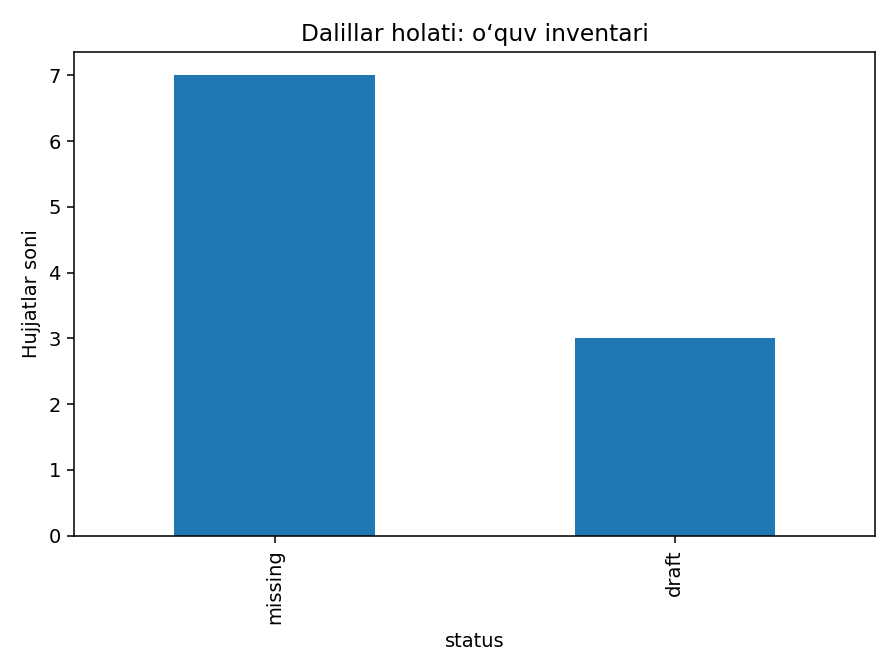

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
